# langchain 

In [1]:
# os module environment variables ko access karne ke liye use hota hai.
import os

# dotenv se load_dotenv function import kar rahe hain.
from dotenv import load_dotenv

# .env file ke variables ko environment mein load karta hai.
load_dotenv()

# GOOGLE_API_KEY ki value read karta hai.
api_key = os.getenv("GOOGLE_API_KEY")

In [ ]:
# LangChain se create_agent function import kar rahe hain.
from langchain.agents import create_agent

# AI agent create kar rahe hain.
agent = create_agent(
    model="gpt-5",  # AI model select kar rahe hain.
    tools=[],  # Abhi agent ko koi external tool nahi diya.
    system_prompt="you are a helpful assistant"  # Agent ka behaviour define kar rahe hain.
)

# Agent object ko display kar rahe hain.
agent

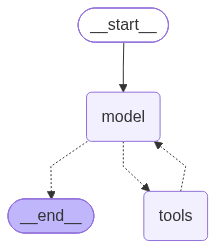

In [2]:
# LangChain se create_agent function import kar rahe hain
from langchain.agents import create_agent

# Weather tool define kar rahe hain
def get_weather(city: str) -> str:
    """Get the weather for a city"""
    # City ka naam use karke weather message return kar rahe hain
    return f"The weather in {city} is sunny."

# GPT-5 model aur weather tool ke saath agent bana rahe hain
agent = create_agent(
    model="gpt-5",
    tools=[get_weather],
    system_prompt="you are a helpful assistant"
)

# Agent ko display kar rahe hain
agent

In [3]:
# Agent ko user ka question dekar run kar rahe hain
response = agent.invoke({
    "messages": [
        {
            "role": "user",  # Message user ki taraf se hai
            "content": "what is weather like in new york "  # User ka question
        }
    ]
})

OpenAIRateLimitError: Error code: 429 - {'error': {'message': 'You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.', 'type': 'insufficient_quota', 'param': None, 'code': 'credit_balance_exhausted'}}

In [ ]:
# Agent ke last message ka content display kar rahe hain
response["messages"][-1].content

In [ ]:
agent.invoke({"messages":"what is weather in new yourk"})#dekho ye fr v ans new york m dega

# # Google gemini model integration

In [ ]:
# Chat model initialize kar rahe hain, init chat model is one of the indirect way to use chatopenai, usko direct niche jis trh kiye h, kr skte
from langchain.chat_models import init_chat_model

model = init_chat_model("openai:gpt-5")

# Model se question pooch rahe hain
response = model.invoke("What is Python?")

# Answer display kar rahe hain
print(response.content)

#Yaad rakhne wali baat: Dono se question pooch sakte ho. Simple AI response ke liye init_chat_model() use karo;
#  jab AI ko tools ke saath task complete karwana ho, tab create_agent() use karo.
#  Agent banane ke liye alag se init_chat_model() call karna zaroori nahi hai.

In [4]:
# LangChain OpenAI se ChatOpenAI class import kar rahe hain
from langchain_openai import ChatOpenAI# chatopen ai k liye requirement.txt m google-genai h

# GPT-4.1 model initialize kar rahe hain
model = ChatOpenAI(model="gpt-4.1")

# Model ko question bhejkar response generate kar rahe hain
response = model.invoke("Hello How are you?")

# Response display kar rahe hain
response

OpenAIRateLimitError: Error code: 429 - {'error': {'message': 'You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.', 'type': 'insufficient_quota', 'param': None, 'code': 'credit_balance_exhausted'}}

In [5]:
# Python ka os module import kar rahe hain
import os

# Gemini model use karne ke liye class import kar rahe hain
from langchain_google_genai import ChatGoogleGenerativeAI

# Gemini 2.5 Flash Lite model initialize kar rahe hain
model = ChatGoogleGenerativeAI(model="gemini-2.5-flash-lite")

# Gemini ko question bhej rahe hain
response = model.invoke("Why do parrots talk?")

# Response object display kar rahe hain
response

GoogleAuthenticationError: Error calling model 'gemini-2.5-flash-lite' (UNAUTHENTICATED): 401 UNAUTHENTICATED. {'error': {'code': 401, 'message': 'API key not valid. Please pass a valid API key.', 'status': 'UNAUTHENTICATED', 'details': [{'@type': 'type.googleapis.com/google.rpc.ErrorInfo', 'reason': 'ACCESS_TOKEN_TYPE_UNSUPPORTED', 'metadata': {'method': 'google.ai.generativelanguage.v1beta.GenerativeService.GenerateContent', 'service': 'generativelanguage.googleapis.com'}}]}}

init_chat_model() ek common entry point hai, jabki ChatOpenAI() aur ChatGoogleGenerativeAI() provider-specific classes hain. Teeno se direct model response le sakti ho. Agent banana ho, toh create_agent() use karogi.

# groq model integration 

In [6]:
# Environment variables access karne ke liye os module import kar rahe hain
import os

# LangChain ka generic chat model function import kar rahe hain
from langchain.chat_models import init_chat_model

# GROQ_API_KEY ko environment variables mein set kar rahe hain
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

# Groq provider ka Qwen3-32B model initialize kar rahe hain
model = init_chat_model("groq:qwen/qwen3-32b")

# Model se question pooch rahe hain
response = model.invoke("Why do parrots talk?")

# Response object display kar rahe hain
response

NotFoundError: Error code: 404 - {'error': {'message': 'The model `qwen/qwen3-32b` does not exist or you do not have access to it.', 'type': 'invalid_request_error', 'code': 'model_not_found'}}

In [9]:
# Environment variables access karne ke liye os module import kar rahe hain
import os

# LangChain se Groq model ki class import kar rahe hain
from langchain_groq import ChatGroq

# Groq ka Qwen3-32B model initialize kar rahe hain
model = ChatGroq(model="openai/gpt-oss-120b")

# Model se question pooch rahe hain
response = model.invoke("Why do parrots talk?")

# Response object display kar rahe hain
response

AIMessage(content='Parrots don’t “talk” in the way humans use language—they’re amazing mimics. Their ability to copy human speech (and other sounds) comes from a combination of anatomy, brain wiring, and social instincts.\n\n| **Factor** | **What it is** | **Why it matters for “talking”** |\n|------------|----------------|---------------------------------|\n| **Vocal anatomy** | A highly flexible syrinx (the bird equivalent of a voice box) and a muscular tongue/beak. | Allows them to produce a wide range of frequencies and rapid changes in pitch, making it easy to imitate human vowels and consonants. |\n| **Brain structure** | A well‑developed **song system** (the nuclei in the forebrain that control vocal learning) and a large **nidopallium** (analogous to parts of the human cortex). | Gives parrots the capacity for **vocal learning**—the ability to hear a sound, store it as a memory, and reproduce it later. |\n| **Social nature** | Parrots are flock animals; in the wild they maintain

Pichhle code mein init_chat_model() use hua tha; is code mein ChatGroq() directly use hua hai. Dono model initialize karte hain

# batch and streaming 


# streaming

In [10]:
# Model se 200 words ka paragraph generate kar rahe hain
response = model.invoke(
    "Write me a 200 words paragraph on Artificial Intelligence"
)

# Response ka actual text display karne ke liye
response.content

'Artificial intelligence, a transformative field of computer science, seeks to create machines capable of performing tasks that traditionally require human cognition such as learning, reasoning, perception, and decision‑making. By leveraging algorithms that process vast datasets, AI systems can recognize patterns, predict outcomes, and adapt their behavior through techniques like machine learning, deep learning, and reinforcement learning. These technologies have permeated numerous domains: autonomous vehicles interpret sensor data to navigate complex environments; medical diagnostics employ neural networks to identify diseases from imaging with accuracy rivaling specialists; natural‑language models generate coherent text, translate languages, and assist in customer service. The rapid progress of AI also raises profound ethical and societal questions, including concerns about bias in training data, privacy infringement, job displacement, and the concentration of power among a few techn

In [11]:
# Streaming se model ka output generate hote hi chunks mein milta hai.
# Isse long responses ko progressively display kar sakte hain.
# stream() ek iterator return karta hai, jo output chunks deta hai.
# Loop se har chunk ko real-time mein process kar sakte hain.

for chunk in model.stream(
    "Write me a 200 words paragraph on Artificial Intelligence"
):
    print(chunk.content, end="|", flush=True)
    #Artificial| Intelligence| (AI)| is| transforming| the| world|...


#Note: Actual output model ke response aur streaming ke chunks par depend karega. Har | ek chunk ke baad print hoga.

||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||

In [12]:
# Model ke response ko streaming ke through chunks mein receive kar rahe hain
for chunk in model.stream("Why do parrots have colorful feathers?"):

    # Har chunk ka text print kar rahe hain; uske baad | lagayenge
    # flush=True se output turant display hota hai
    print(chunk.text, end="|", flush=True)

||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||Par|rots| are| famous| for| their| brilliant| reds|,| greens|,| blues|,| and| yell|ows|,| and| those| colors| didn|’t| appear| by| accident|.| | Their| vivid| plum|age| is| the| result| of| several| evolutionary| forces| that| work| together|:

||| Factor| || How| it| works| || What| it| gives| the| bird| |
|||--------|||--------------|||----------------|--------||
||| **|Sex|ual| selection|**| || In| many| par|rot| species|,| individuals| with| brighter|,| more| saturated| colors| are| judged| “|higher| quality|”| by| potential| mates|.| Bright|ness| can| signal| good| health|,| a| diet| rich| in| pigments|,| and| strong| genetics|.| || M|ales| (|and| sometimes| females|)| evolve| ever|‑|more| striking| hues| because| those| individuals| win| more| breeding| opportunities|.| |
||| **|Species|‑|recogn|ition| signaling|**| || Par|rots| often| live| in| dense|,| mult|icol|ored| tropical| forests| where| many| bird| species| 

# batch
execution parallel ho sakta hai, lekin tumhara for loop responses ko sequentially display karta hai.

Yaad rakho: batch() multiple inputs ko ek saath handle karta hai; actual parallelism model integration aur configuration par depend karta hai.


In [13]:
# 3 questions ko ek saath model ko bhej rahe hain
responses = model.batch([
    "Why do parrots have colorful feathers?",
    "How do airplanes fly?",
    "What is quantum computing?"
])

# Har response ko ek-ek karke print kar rahe hain
for response in responses:
    print(response)

content='Parrots are famous for their vivid, multicolored plumage, and several evolutionary and biological factors combine to explain why they look the way they do.\n\n### 1. **Sexual selection**\n- **Mate choice:** In many bird species, brighter colors are a signal of good health and genetic quality. A male (or sometimes a female) with more intense, well‑structured colors is often more attractive to potential mates, increasing its chances of reproducing.\n- **Competition:** Bright plumage can also serve as a “badge of status,” letting rivals know who’s the stronger or more dominant individual without the need for a physical fight.\n\n### 2. **Species recognition**\n- **Avoiding hybridization:** In habitats where several parrot species coexist, distinct color patterns help individuals quickly recognize members of their own species, which is crucial for successful breeding.\n- **Social cohesion:** Within a flock, consistent coloration can reinforce group identity and facilitate coordina

In [14]:
# Multiple questions ko batch mein process kar rahe hain
responses = model.batch(
    [
        "Why do parrots have colorful feathers?",
        "How do airplanes fly?",
        "What is quantum computing?",
        "What is machine learning?",
        "What is LangChain?",
        "What is Python?",
        "What is artificial intelligence?",
        "What is deep learning?",
        "What is an AI agent?",
        "What is RAG?"
    ],
    config={
        "max_concurrency": 5  # Maximum 5 calls ek saath execute ho sakti hain
    }
)

# Har response ko ek-ek karke display kar rahe hain
for response in responses:
    print(response.content)
    print("-----")

RateLimitError: Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-120b` in organization `org_01m5w9rxe6ekz9kqf0vm9mhvs6` service tier `on_demand` on tokens per minute (TPM): Limit 8000, Used 7787, Requested 1259. Please try again in 7.845s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}